## Access Morlenn Mixed Layer Properties

Mixed Layer Properties (MLD, N2max) reconstruction in the North Atlantic Ocean, Mediterranean sea and equatorial region using Morlenn algorithm, baseline and assim version within ESA UpperDyn project.

* Original Data Source: ...
* Reference:  OceanDataLab (Lucile Gaultier, Parth Tripathi)
* OSC entry: ...
* License: CC-BY-4.0

In [1]:
import xarray as xr

In [2]:
zarr_href1 = 'https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/upperdyn-morlenn/morlenn_baseline.zarr'
zarr_href2 = 'https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/upperdyn-morlenn/morlenn_assim.zarr'

## Baseline model

In [3]:
ds = xr.open_zarr(zarr_href1)
ds

<xarray.Dataset> Size: 300GB
Dimensions:                (time: 37984, latitude: 385, longitude: 569)
Coordinates:
  * time                   (time) datetime64[ns] 304kB 2011-01-01 ... 2023-12...
  * latitude               (latitude) float32 2kB -6.0 -5.75 -5.5 ... 89.75 90.0
  * longitude              (longitude) float32 2kB -100.0 -99.75 ... 41.75 42.0
Data variables:
    assim_mask             (time, latitude, longitude) int8 8GB dask.array<chunksize=(120, 385, 569), meta=np.ndarray>
    interp_fraction        (time, latitude, longitude) float32 33GB dask.array<chunksize=(120, 385, 569), meta=np.ndarray>
    mld                    (time, latitude, longitude) float32 33GB dask.array<chunksize=(120, 385, 569), meta=np.ndarray>
    mld_std                (time, latitude, longitude) float32 33GB dask.array<chunksize=(120, 385, 569), meta=np.ndarray>
    n1_dist_km             (time, latitude, longitude) float32 33GB dask.array<chunksize=(120, 385, 569), meta=np.ndarray>
    n1_dt_days             (time, latitude, longitude) float32 33GB dask.array<chunksize=(120, 385, 569), meta=np.ndarray>
    N2                     (time, latitude, longitude) float32 33GB dask.array<chunksize=(120, 385, 569), meta=np.ndarray>
    N2_quality_flag        (time, latitude, longitude) uint8 8GB dask.array<chunksize=(120, 385, 569), meta=np.ndarray>
    N2_std                 (time, latitude, longitude) float32 33GB dask.array<chunksize=(120, 385, 569), meta=np.ndarray>
    n_neighbors            (time, latitude, longitude) int8 8GB dask.array<chunksize=(120, 385, 569), meta=np.ndarray>
    sea_ice_concentration  (time, latitude, longitude) float32 33GB dask.array<chunksize=(120, 385, 569), meta=np.ndarray>
    valid_input            (time, latitude, longitude) int8 8GB dask.array<chunksize=(120, 385, 569), meta=np.ndarray>
Attributes: (12/26)
    source_daily_file:          data/maps/output_daily_025_v2/merged_025_2011...
    source_bathymetry_file:     data/bathy/inputs_bathymetry.nc
    checkpoint:                 prod/train/canonical/baseline/baseline.pt
    config:                     prod/config/profiles/baseline_prod.toml
    mld_postprocess:            clamped to local bathymetry depth where eleva...
    created_utc:                2026-07-26T11:19:43+00:00
    ...                         ...
    source:                     Morlenn algorithm, checkpoint prod/train/cano...
    upperdyn_seaice_masked:     false
    seaice_source:              AMSR2 ASI n6250 v5.4, University of Bremen (d...
    seaice_threshold_pct:       30.0
    seaice_masked_points:       0
    producer:                   OceanDataLab (Lucile Gaultier, Parth Tripathi)

In [4]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Choose date
date = "2020-06-01"

# Select the air-sea CO2 flux for that date
n2 = ds["N2"].sel(
    longitude=slice(-6.062, 36.06),
    latitude=slice(30.27, 45.98),
)
n2 = n2.sel(time=date, drop=True, method="nearest")

n2

<xarray.DataArray 'N2' (latitude: 62, longitude: 169)> Size: 42kB
dask.array<getitem, shape=(62, 169), dtype=float32, chunksize=(62, 169), chunktype=numpy.ndarray>
Coordinates:
  * latitude   (latitude) float32 248B 30.5 30.75 31.0 ... 45.25 45.5 45.75
  * longitude  (longitude) float32 676B -6.0 -5.75 -5.5 ... 35.5 35.75 36.0
Attributes:
    units:                  s-2
    long_name:              UpperDyn inferred N2
    standard_name:          square_of_brunt_vaisala_frequency_in_sea_water
    ancillary_variables:    N2_std
    comment:                Vertical maximum over the water column of the squ...
    coverage_content_type:  modelResult

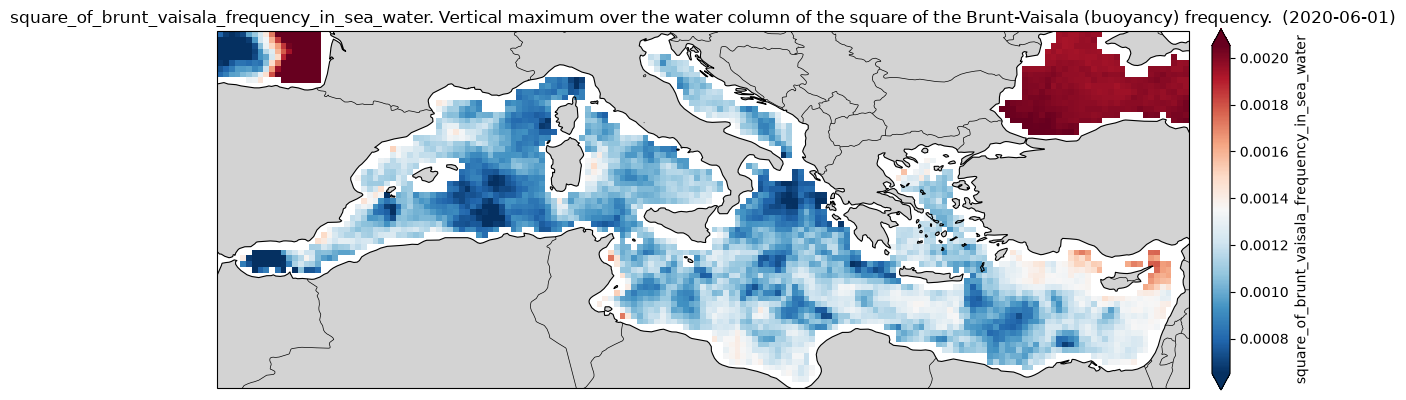

In [5]:

# use the xarray plotting interface to create a map
img = n2.plot.imshow(
    subplot_kws={"projection": ccrs.PlateCarree()},
    transform=ccrs.PlateCarree(),
    size=4,
    aspect=3,
    robust=True,
    cmap="RdBu_r",
    cbar_kwargs={"label": "square_of_brunt_vaisala_frequency_in_sea_water", "pad": 0.02},
)

fig, ax = img.figure, img.axes

ax.add_feature(cfeature.LAND, facecolor="lightgray")
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)

ax.set_title(f"square_of_brunt_vaisala_frequency_in_sea_water. Vertical maximum over the water column of the square of the Brunt-Vaisala (buoyancy) frequency.  ({date})")

fig.tight_layout()

## Assim Model

In [6]:
ds = xr.open_zarr(zarr_href2)
ds

<xarray.Dataset> Size: 300GB
Dimensions:                (time: 37984, latitude: 385, longitude: 569)
Coordinates:
  * time                   (time) datetime64[ns] 304kB 2011-01-01 ... 2023-12...
  * latitude               (latitude) float32 2kB -6.0 -5.75 -5.5 ... 89.75 90.0
  * longitude              (longitude) float32 2kB -100.0 -99.75 ... 41.75 42.0
Data variables:
    assim_mask             (time, latitude, longitude) int8 8GB dask.array<chunksize=(120, 385, 569), meta=np.ndarray>
    interp_fraction        (time, latitude, longitude) float32 33GB dask.array<chunksize=(120, 385, 569), meta=np.ndarray>
    mld                    (time, latitude, longitude) float32 33GB dask.array<chunksize=(120, 385, 569), meta=np.ndarray>
    mld_std                (time, latitude, longitude) float32 33GB dask.array<chunksize=(120, 385, 569), meta=np.ndarray>
    n1_dist_km             (time, latitude, longitude) float32 33GB dask.array<chunksize=(120, 385, 569), meta=np.ndarray>
    n1_dt_days             (time, latitude, longitude) float32 33GB dask.array<chunksize=(120, 385, 569), meta=np.ndarray>
    N2                     (time, latitude, longitude) float32 33GB dask.array<chunksize=(120, 385, 569), meta=np.ndarray>
    N2_quality_flag        (time, latitude, longitude) uint8 8GB dask.array<chunksize=(120, 385, 569), meta=np.ndarray>
    N2_std                 (time, latitude, longitude) float32 33GB dask.array<chunksize=(120, 385, 569), meta=np.ndarray>
    n_neighbors            (time, latitude, longitude) int8 8GB dask.array<chunksize=(120, 385, 569), meta=np.ndarray>
    sea_ice_concentration  (time, latitude, longitude) float32 33GB dask.array<chunksize=(120, 385, 569), meta=np.ndarray>
    valid_input            (time, latitude, longitude) int8 8GB dask.array<chunksize=(120, 385, 569), meta=np.ndarray>
Attributes: (12/26)
    source_daily_file:          data/maps/output_daily_025_v2/merged_025_2011...
    source_bathymetry_file:     data/bathy/inputs_bathymetry.nc
    checkpoint:                 prod/train/canonical/assim_prod/assim_prod.pt
    config:                     prod/config/profiles/assim_prod.toml
    mld_postprocess:            clamped to local bathymetry depth where eleva...
    created_utc:                2026-07-29T05:18:45+00:00
    ...                         ...
    source:                     Morlenn algorithm, checkpoint prod/train/cano...
    upperdyn_seaice_masked:     false
    seaice_source:              AMSR2 ASI n6250 v5.4, University of Bremen (d...
    seaice_threshold_pct:       30.0
    seaice_masked_points:       0
    producer:                   OceanDataLab (Lucile Gaultier, Parth Tripathi)

In [7]:
# Choose date
date = "2020-06-01"

# Select the air-sea CO2 flux for that date
n2 = ds["N2"].sel(
    longitude=slice(-6.062, 36.06),
    latitude=slice(30.27, 45.98),
)
n2 = n2.sel(time=date, drop=True, method="nearest")

n2

<xarray.DataArray 'N2' (latitude: 62, longitude: 169)> Size: 42kB
dask.array<getitem, shape=(62, 169), dtype=float32, chunksize=(62, 169), chunktype=numpy.ndarray>
Coordinates:
  * latitude   (latitude) float32 248B 30.5 30.75 31.0 ... 45.25 45.5 45.75
  * longitude  (longitude) float32 676B -6.0 -5.75 -5.5 ... 35.5 35.75 36.0
Attributes:
    units:                  s-2
    long_name:              UpperDyn inferred N2
    standard_name:          square_of_brunt_vaisala_frequency_in_sea_water
    ancillary_variables:    N2_std
    comment:                Vertical maximum over the water column of the squ...
    coverage_content_type:  modelResult

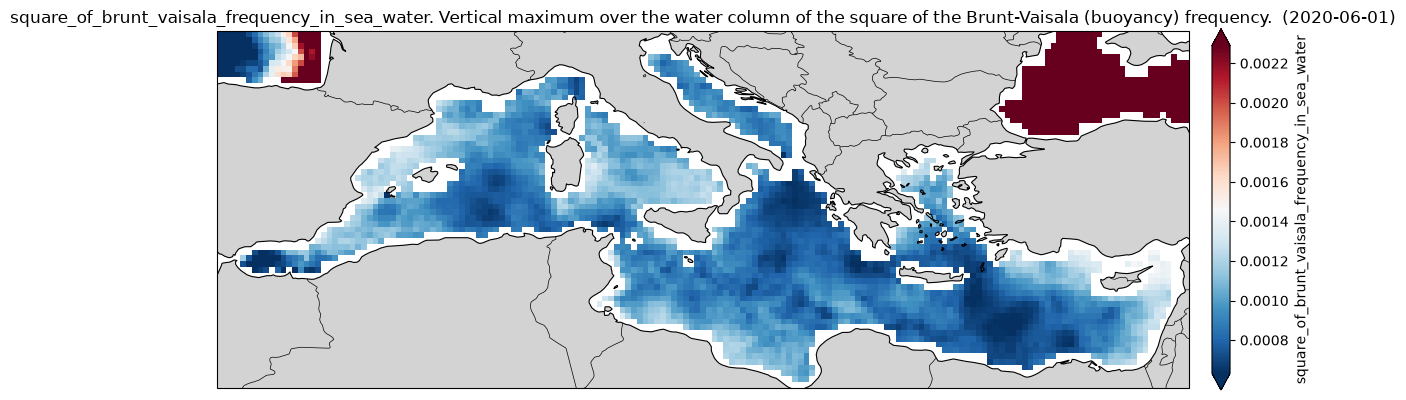

In [8]:

# use the xarray plotting interface to create a map
img = n2.plot.imshow(
    subplot_kws={"projection": ccrs.PlateCarree()},
    transform=ccrs.PlateCarree(),
    size=4,
    aspect=3,
    robust=True,
    cmap="RdBu_r",
    cbar_kwargs={"label": "square_of_brunt_vaisala_frequency_in_sea_water", "pad": 0.02},
)

fig, ax = img.figure, img.axes

ax.add_feature(cfeature.LAND, facecolor="lightgray")
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)

ax.set_title(f"square_of_brunt_vaisala_frequency_in_sea_water. Vertical maximum over the water column of the square of the Brunt-Vaisala (buoyancy) frequency.  ({date})")

fig.tight_layout()